# MH6805 | Group 30 | CHEN WEIQI | G2605197A
## Supplementary Exploratory Data Analysis (EDA)

**Scope:** Fixed training data only (`n=9,764`). **Target:** `Revenue=True`. **Seed:** `6805`.  

## 1 | Imports and data loading

Use the shared training CSV. Outputs are saved to `eda_figures/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

SEED = 6805
RNG = np.random.default_rng(SEED)
BLUE, ORANGE, GRAY = "#34798D", "#E6794E", "#687987"
plt.rcParams.update({"figure.dpi": 105, "savefig.dpi": 155, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11, "font.size": 9})

def locate_train():
    roots = [Path.cwd(), Path.cwd() / "data", Path.cwd() / "tree base",
             Path.cwd().parent, Path.cwd().parent / "data"]
    for root in roots:
        path = root / "online_shoppers_train_fixed.csv"
        if path.is_file():
            return path
    raise FileNotFoundError("Place online_shoppers_train_fixed.csv in the notebook working directory (or data/).")

TRAIN_FILE = locate_train()
df = pd.read_csv(TRAIN_FILE)
assert "Revenue" in df.columns
assert len(df) == 9764, "Check shared training data version."
df["Revenue"] = df["Revenue"].astype(bool)
CAT = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend"]
NUM = [c for c in df.columns if c not in CAT + ["Revenue"]]
PRIMARY_NUM = [c for c in NUM if c != "PageValues"]
figdir = Path("eda_figures")
figdir.mkdir(exist_ok=True)

def savefig(name):
    plt.savefig(figdir / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

print(f"Training source: {TRAIN_FILE} | shape={df.shape} | figures={figdir.resolve()}")

Training source: c:\Users\Welkin\OneDrive - HKUST Connect\Desktop\NTU_academic\semester1\6805\group project\tree base\online_shoppers_train_fixed.csv | shape=(9764, 18) | figures=C:\Users\Welkin\OneDrive - HKUST Connect\Desktop\NTU_academic\semester1\6805\group project\tree base\eda_figures


## 2 | Data audit

Review schema, missingness, duplicates and plausible numeric ranges. No rows are removed.

In [2]:
audit = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
}).rename_axis("feature")
display(audit)
print(f"Total missing cells: {df.isna().sum().sum()}")
print(f"Exact duplicate rows in fixed training split: {df.duplicated().sum()}")
print(f"Negative numeric entries: {(df[NUM] < 0).sum().sum()}")
print("Class counts:", df["Revenue"].value_counts().to_dict())

,type,missing,unique
feature,,,
Administrative,int64,0,27
Administrative_Duration,float64,0,2788
Informational,int64,0,15
Informational_Duration,float64,0,1053
ProductRelated,int64,0,299
ProductRelated_Duration,float64,0,7825
BounceRates,float64,0,1580
ExitRates,float64,0,3969
PageValues,float64,0,2144


Total missing cells: 0
Exact duplicate rows in fixed training split: 0
Negative numeric entries: 0
Class counts: {False: 8238, True: 1526}


## 3 | Class balance

Purchase is the minority class; accuracy alone is insufficient.

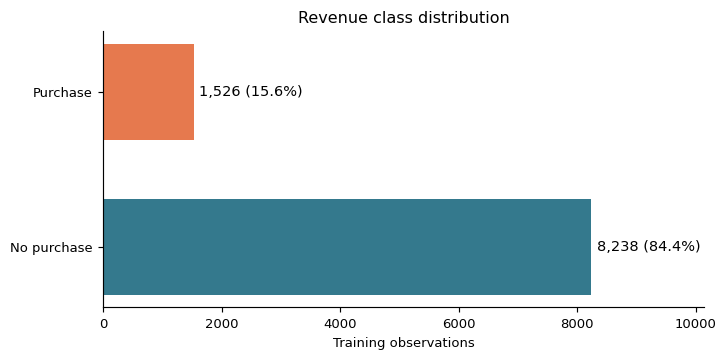

In [3]:
counts = df["Revenue"].value_counts().reindex([False, True])
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(["No purchase", "Purchase"], counts.values, color=[BLUE, ORANGE], height=0.62)
for bar, c in zip(bars, counts.values):
    ax.text(bar.get_width() + 90, bar.get_y() + bar.get_height()/2,
            f"{c:,} ({c/len(df):.1%})", va="center", fontsize=10)
ax.set_xlim(0, counts.max() * 1.23)
ax.set(xlabel="Training observations", title="Revenue class distribution")
plt.tight_layout(); savefig("01_class_balance")

## 4 | Zero inflation and sparsity

Many engagement and monetary variables have a large mass at zero.

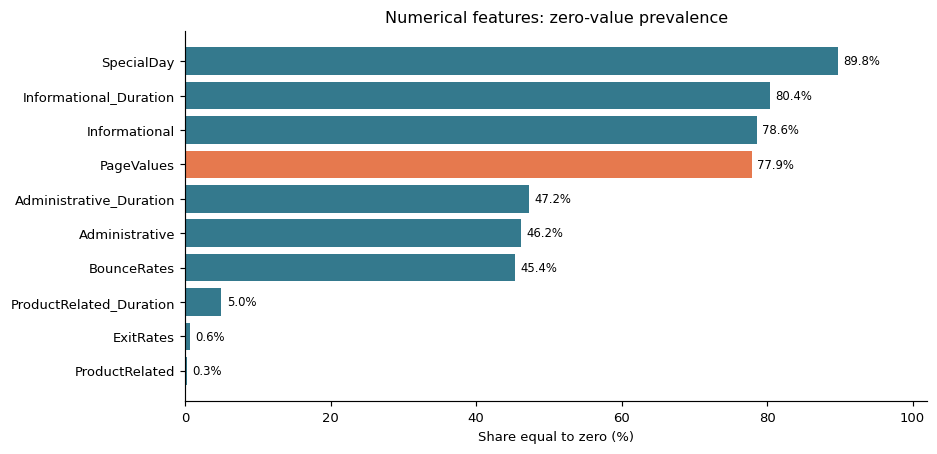

In [4]:
zero_share = (df[NUM].eq(0).mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.4))
colors = [ORANGE if c == "PageValues" else BLUE for c in zero_share.index]
ax.barh(zero_share.index, zero_share.values, color=colors)
for i,v in enumerate(zero_share.values): ax.text(v+0.75, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, 102)
ax.set(xlabel="Share equal to zero (%)", title="Numerical features: zero-value prevalence")
plt.tight_layout(); savefig("02_zero_rates")

## 5 | Numerical distributions

Histograms expose skew, sparse variables and extreme values.

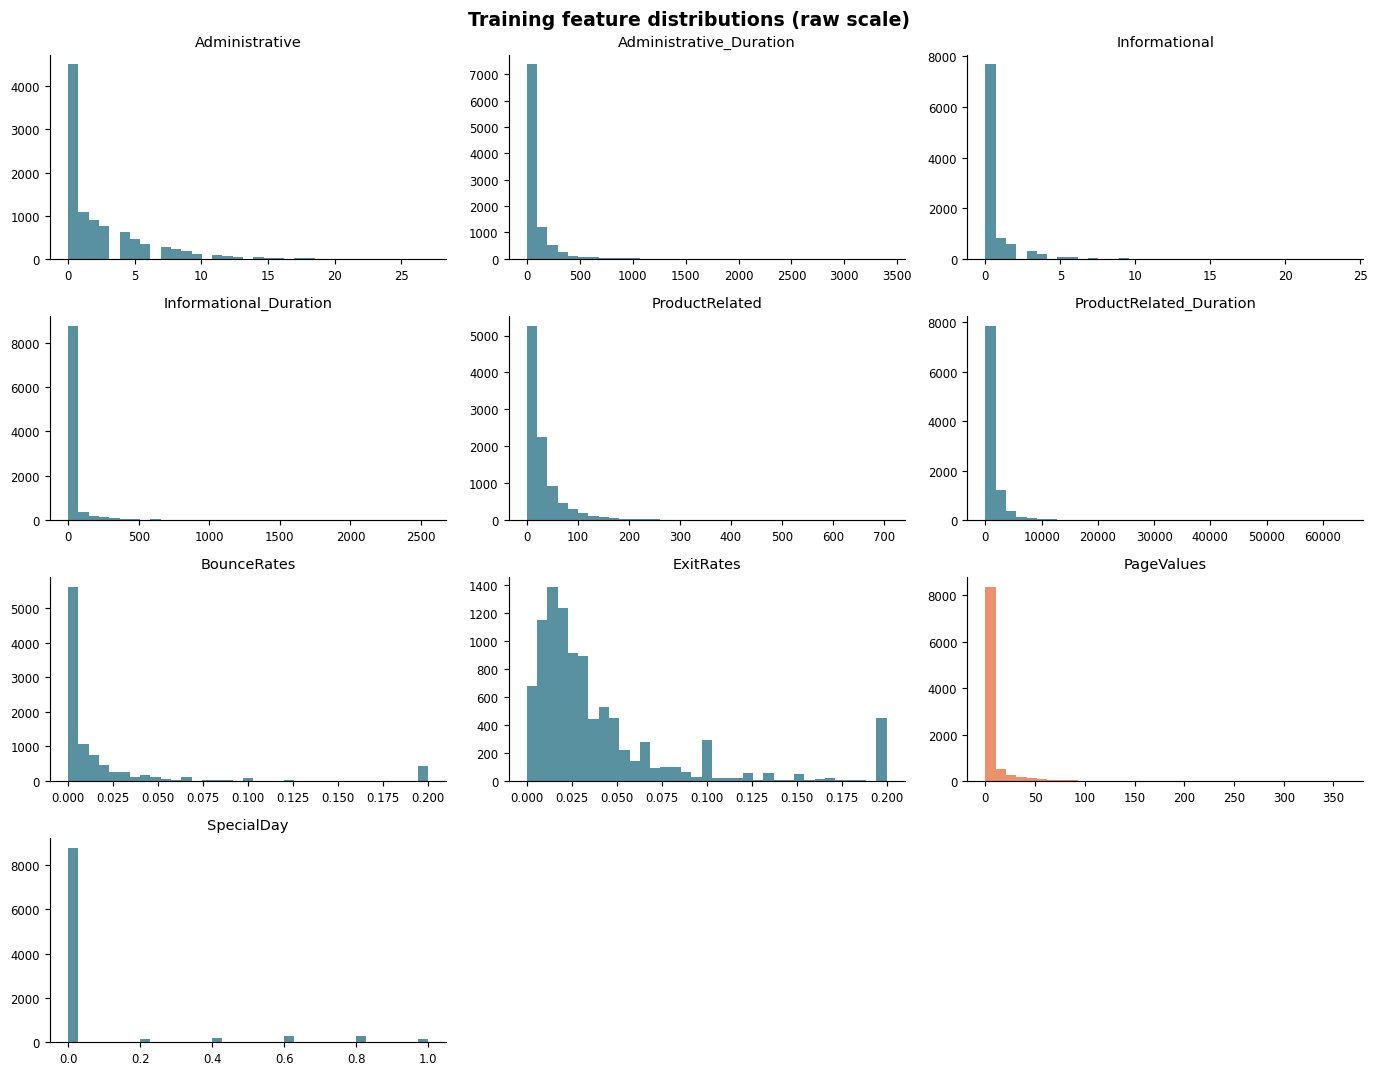

In [5]:
cols = NUM
fig, axes = plt.subplots(4, 3, figsize=(13.2, 10.4))
for ax, col in zip(axes.ravel(), cols):
    ax.hist(df[col].dropna(), bins=35, color=ORANGE if col == "PageValues" else BLUE,
            alpha=0.82, edgecolor="none")
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
for ax in axes.ravel()[len(cols):]: ax.axis("off")
fig.suptitle("Training feature distributions (raw scale)", weight="bold", fontsize=13)
plt.tight_layout(); savefig("03_numeric_distributions")

## 6 | Long tails and upper quantiles

The `log1p` view is descriptive here; it does not alter the training features.

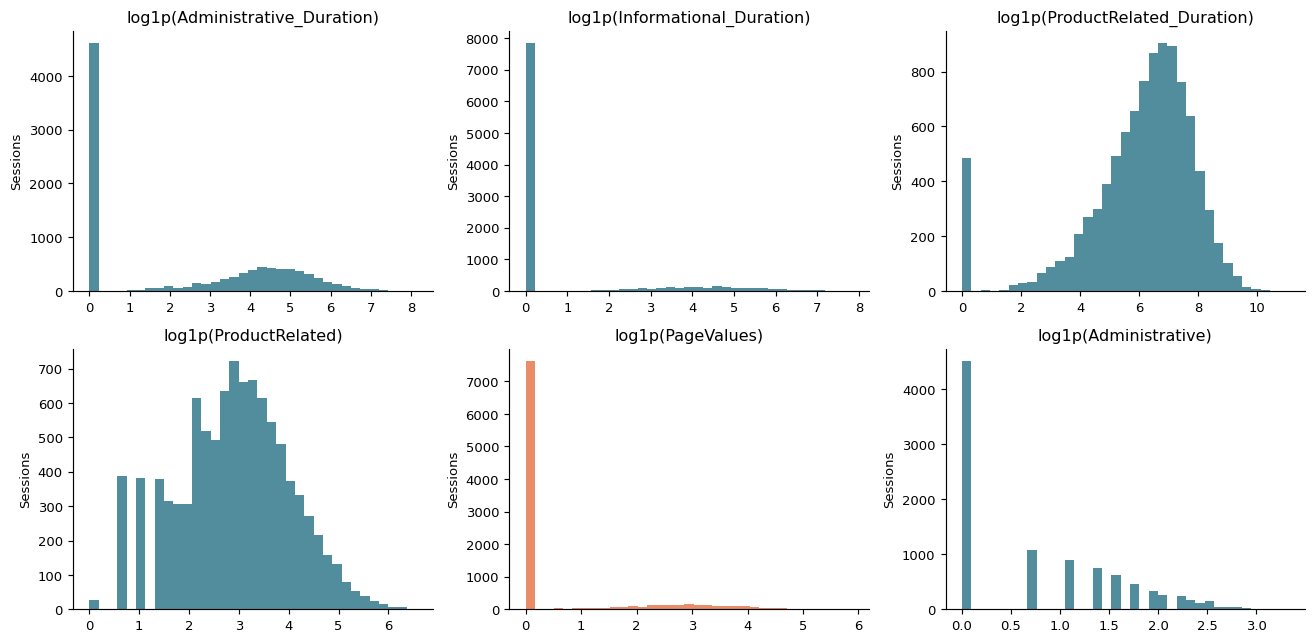

,Median,P90,P99,Max
Administrative,1.000,7.000,14.000,27.000
Administrative_Duration,9.000,225.485,851.382,3398.750
Informational,0.000,2.000,6.000,24.000
Informational_Duration,0.000,74.350,728.571,2549.375
ProductRelated,18.000,75.000,223.370,705.000
ProductRelated_Duration,613.945,2880.043,9030.088,63973.522
BounceRates,0.003,0.050,0.200,0.200
ExitRates,0.025,0.100,0.200,0.200
PageValues,0.000,18.614,85.890,361.764
SpecialDay,0.000,0.200,1.000,1.000


In [6]:
tail_cols = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration",
             "ProductRelated", "PageValues", "Administrative"]
fig, axes = plt.subplots(2, 3, figsize=(12.6, 6.2))
for ax, col in zip(axes.ravel(), tail_cols):
    ax.hist(np.log1p(df[col]), bins=35, color=BLUE if col != "PageValues" else ORANGE, alpha=.85)
    ax.set(title=f"log1p({col})", ylabel="Sessions")
plt.tight_layout(); savefig("04_long_tail_log1p")
q = df[NUM].quantile([0.5,0.9,0.99,1]).T
q.columns=["Median","P90","P99","Max"]
display(q.round(3))

## 7 | Buyer vs non-buyer distributions

Class-conditional distributions reveal associations, with no causal interpretation.

TypeError: boxplot() got an unexpected keyword argument 'tick_labels'

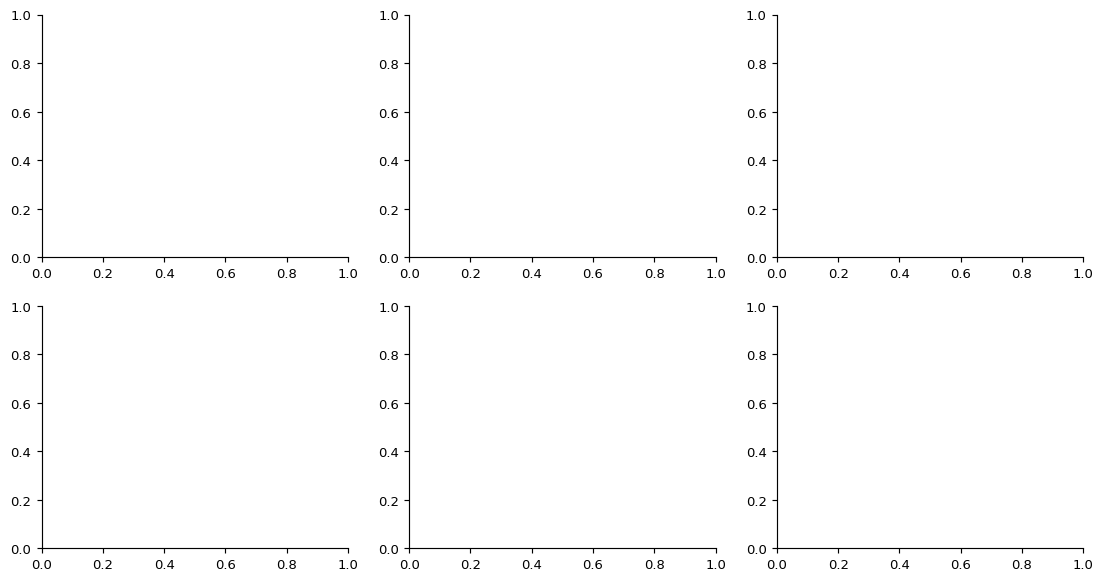

In [7]:
sel = ["ProductRelated", "ProductRelated_Duration", "Administrative_Duration",
       "Informational_Duration", "BounceRates", "ExitRates"]
fig, axes = plt.subplots(2, 3, figsize=(12.8, 6.6))
for ax, col in zip(axes.ravel(), sel):
    a = np.log1p(df.loc[~df.Revenue, col].to_numpy())
    b = np.log1p(df.loc[df.Revenue, col].to_numpy())
    bp = ax.boxplot([a,b], tick_labels=["No purchase", "Purchase"], showfliers=False, patch_artist=True,
                    medianprops={"color":"#18242F", "linewidth":1.3})
    for p, color in zip(bp['boxes'], [BLUE, ORANGE]):p.set(facecolor=color, alpha=.75)
    ax.set(title=col, ylabel="log1p(value)")
plt.tight_layout(); savefig("05_class_conditional_boxplots")

## 8 | Correlation and redundancy

Spearman correlations highlight rank associations and collinear count-duration pairs.

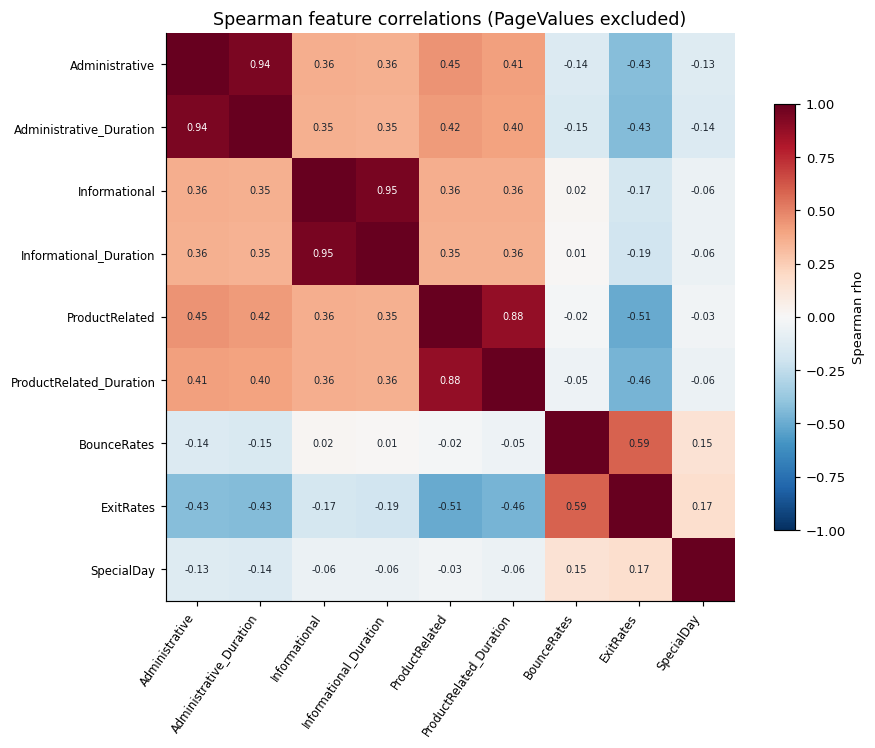

,,Spearman rho
Informational,Informational_Duration,0.952
Administrative,Administrative_Duration,0.940
ProductRelated,ProductRelated_Duration,0.877
BounceRates,ExitRates,0.587
ProductRelated,ExitRates,-0.506
ProductRelated_Duration,ExitRates,-0.461
Administrative,ProductRelated,0.453
Administrative_Duration,ExitRates,-0.434
Administrative,ExitRates,-0.428
Administrative_Duration,ProductRelated,0.424


In [ ]:
corr = df[PRIMARY_NUM].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.2, 7.2))
im=ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        if i != j: ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=6.7,
                             color="white" if abs(corr.iloc[i,j]) > .64 else "#1B242E")
fig.colorbar(im, ax=ax, shrink=.75, label="Spearman rho")
ax.set_title("Spearman feature correlations (PageValues excluded)", fontsize=12)
plt.tight_layout(); savefig("06_spearman_correlation")
pairs = corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack().sort_values(key=abs, ascending=False)
display(pairs.head(10).rename("Spearman rho").round(3).to_frame())

## 9 | Numeric association with Revenue

Positive and negative correlations summarize marginal rank relationships.

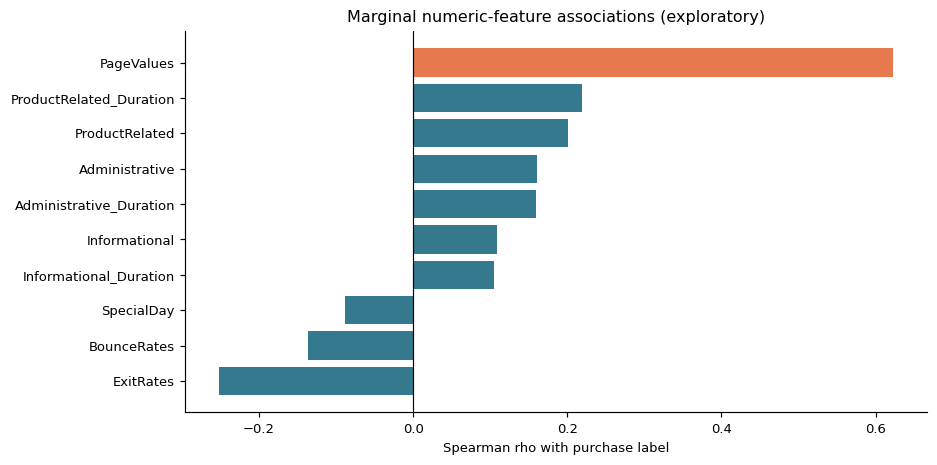

,Spearman rho
ExitRates,-0.252
BounceRates,-0.136
SpecialDay,-0.089
Informational_Duration,0.106
Informational,0.109
Administrative_Duration,0.160
Administrative,0.161
ProductRelated,0.201
ProductRelated_Duration,0.219
PageValues,0.623


In [ ]:
numeric_rho = df[NUM + ["Revenue"]].assign(Revenue=df.Revenue.astype(int)).corr(method="spearman")["Revenue"].drop("Revenue").sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(numeric_rho.index, numeric_rho.values,
        color=[ORANGE if c == "PageValues" else BLUE for c in numeric_rho.index])
ax.axvline(0, lw=.8, c="black")
ax.set(xlabel="Spearman rho with purchase label", title="Marginal numeric-feature associations (exploratory)")
plt.tight_layout(); savefig("07_numeric_target_spearman")
display(numeric_rho.rename("Spearman rho").round(3).to_frame())

## 10 | Categorical feature mix

Integer codes (e.g., Browser, TrafficType) are categorical labels.

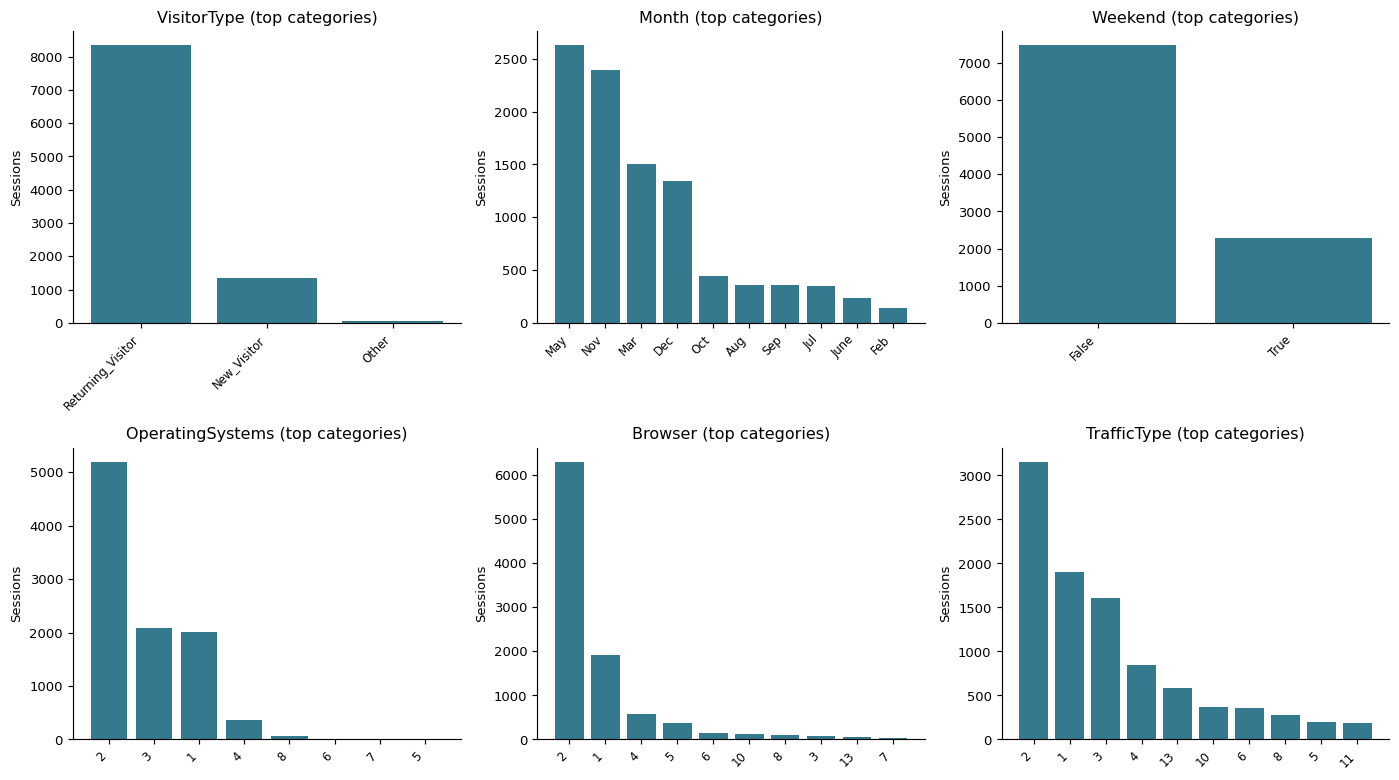

In [ ]:
view = ["VisitorType", "Month", "Weekend", "OperatingSystems", "Browser", "TrafficType"]
fig, axes = plt.subplots(2,3, figsize=(13.4,7.5))
for ax, col in zip(axes.ravel(), view):
    ct=df[col].astype(str).value_counts().head(10)
    ax.bar(range(len(ct)), ct.values, color=BLUE)
    ax.set_xticks(range(len(ct)), ct.index, rotation=45, ha="right", fontsize=8)
    ax.set(title=f"{col} (top categories)", ylabel="Sessions")
plt.tight_layout(); savefig("08_categorical_counts")

## 11 | Category-level purchase rates

Rates are descriptive; small groups are less stable.

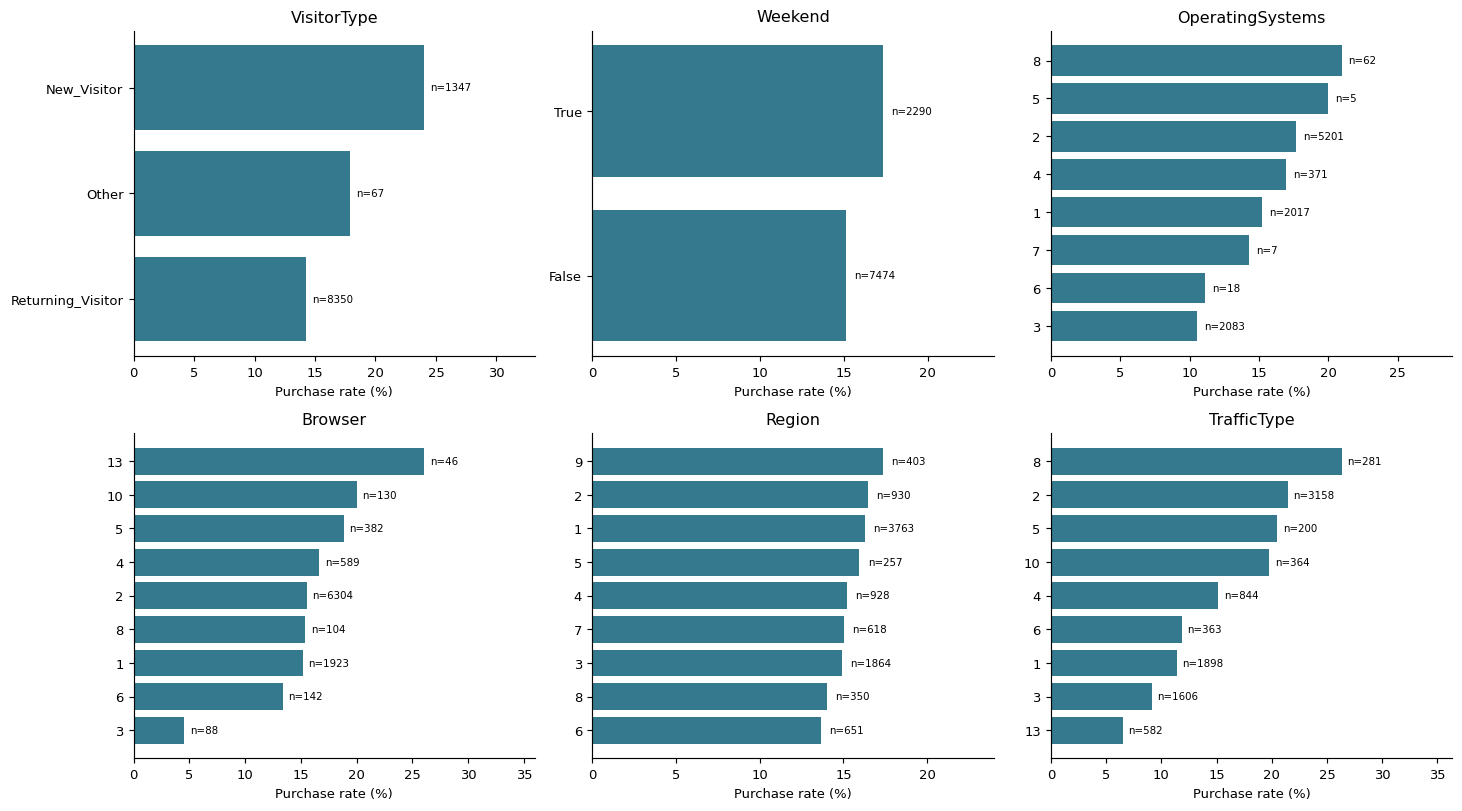

In [ ]:
cats = ["VisitorType","Weekend","OperatingSystems","Browser","Region","TrafficType"]
fig, axes = plt.subplots(2,3, figsize=(14,7.8))
for ax, col in zip(axes.ravel(), cats):
    agg=df.groupby(col, observed=True).Revenue.agg(n="size",rate="mean")
    agg=agg.sort_values("n",ascending=False).head(9).sort_values("rate")
    ax.barh(agg.index.astype(str), agg.rate * 100, color=BLUE)
    for i,(v,n) in enumerate(zip(agg.rate,agg.n)):
        ax.text(v*100+0.5,i,f"n={n}",va="center",fontsize=7)
    ax.set(title=col,xlabel="Purchase rate (%)",xlim=(0,max(12,agg.rate.max()*100*1.38)))
plt.tight_layout(); savefig("09_category_purchase_rates")

## 12 | Monthly patterns

Month groups may reflect seasonality and dataset composition; only one year is available.

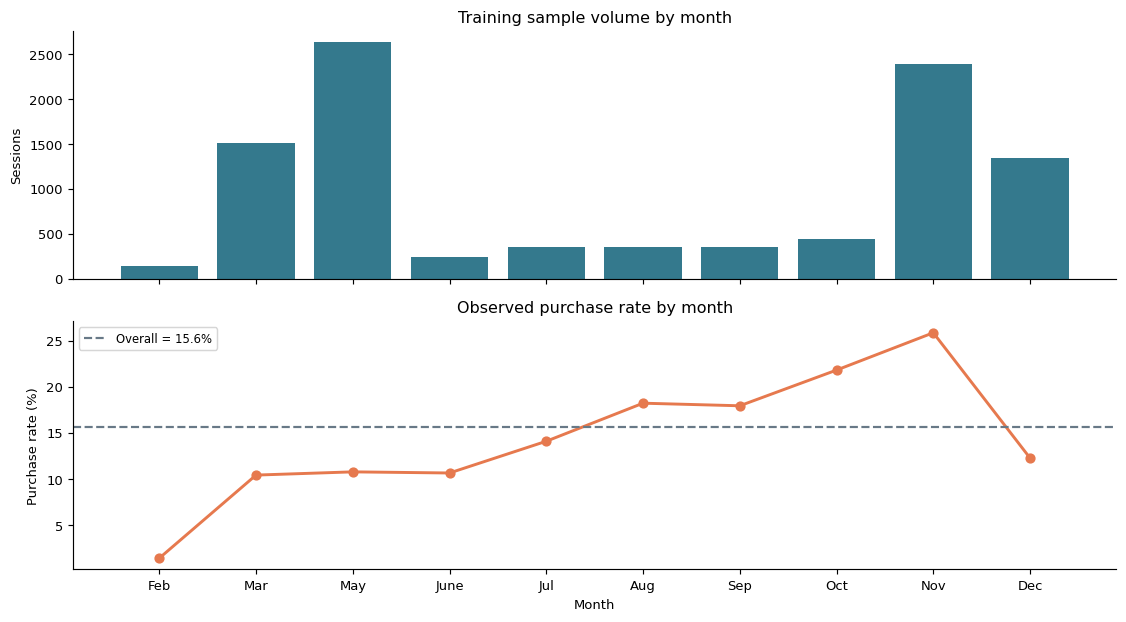

,n,Purchase rate (%)
Month,,
Feb,143,1.40
Mar,1508,10.41
May,2630,10.76
June,235,10.64
Jul,348,14.08
Aug,357,18.21
Sep,357,17.93
Oct,445,21.80
Nov,2395,25.85


In [ ]:
MONTHS = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_stats = df.groupby("Month").Revenue.agg(n="size",purchase_rate="mean").reindex(MONTHS)
fig,(ax1,ax2)=plt.subplots(2,1,figsize=(10.8,6),sharex=True)
ax1.bar(range(len(month_stats)), month_stats.n, color=BLUE)
ax1.set(ylabel="Sessions",title="Training sample volume by month")
ax2.plot(range(len(month_stats)),100*month_stats.purchase_rate,marker="o",color=ORANGE,lw=2.0)
ax2.axhline(100*df.Revenue.mean(), ls="--",color=GRAY,label=f"Overall = {df.Revenue.mean():.1%}")
ax2.set(ylabel="Purchase rate (%)",xlabel="Month",title="Observed purchase rate by month")
ax2.set_xticks(range(len(month_stats)),MONTHS)
ax2.legend(loc="upper left",fontsize=8)
plt.tight_layout();savefig("10_month_volume_purchase_rate")
display(month_stats.assign(purchase_rate=lambda t:100*t.purchase_rate).rename(columns={"purchase_rate":"Purchase rate (%)"}).round(2))

## 13 | Visitor-type and month interaction

Cells with fewer than 25 sessions are masked to avoid visual overinterpretation.

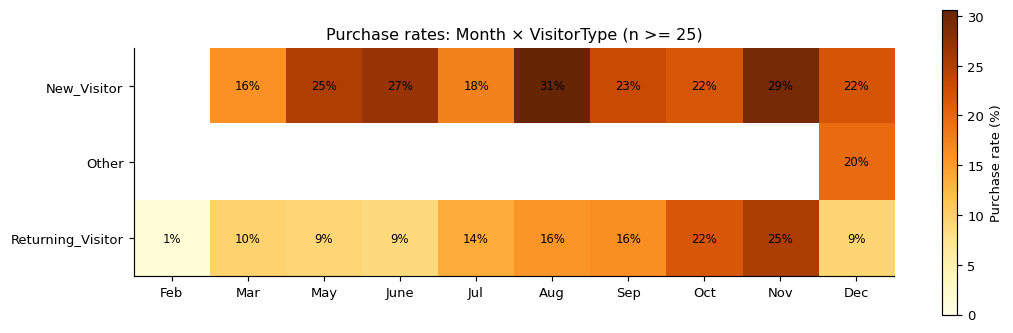

In [ ]:
grp = df.groupby(["Month","VisitorType"],observed=True).Revenue.agg(n="size",rate="mean").reset_index()
rate=grp.pivot(index="VisitorType",columns="Month",values="rate").reindex(columns=MONTHS)
counts_=grp.pivot(index="VisitorType",columns="Month",values="n").reindex(columns=MONTHS)
rate=rate.where(counts_>=25)
fig,ax=plt.subplots(figsize=(10.5,3.9))
im=ax.imshow(rate.to_numpy()*100,cmap="YlOrBr",vmin=0,vmax=max(30,float(np.nanmax(rate))*100))
ax.set_xticks(range(len(rate.columns)),rate.columns)
ax.set_yticks(range(len(rate.index)),rate.index)
for i in range(len(rate.index)):
    for j in range(len(rate.columns)):
        v=rate.iloc[i,j]
        if pd.notna(v):ax.text(j,i,f"{v:.0%}",ha="center",va="center",fontsize=8)
fig.colorbar(im,ax=ax,label="Purchase rate (%)",shrink=.8)
ax.set_title("Purchase rates: Month × VisitorType (n >= 25)")
plt.tight_layout(); savefig("11_month_visitor_heatmap")

## 14 | Purchase rate versus numeric feature level

Quantile groups are computed for visualization only; no thresholds enter model training.

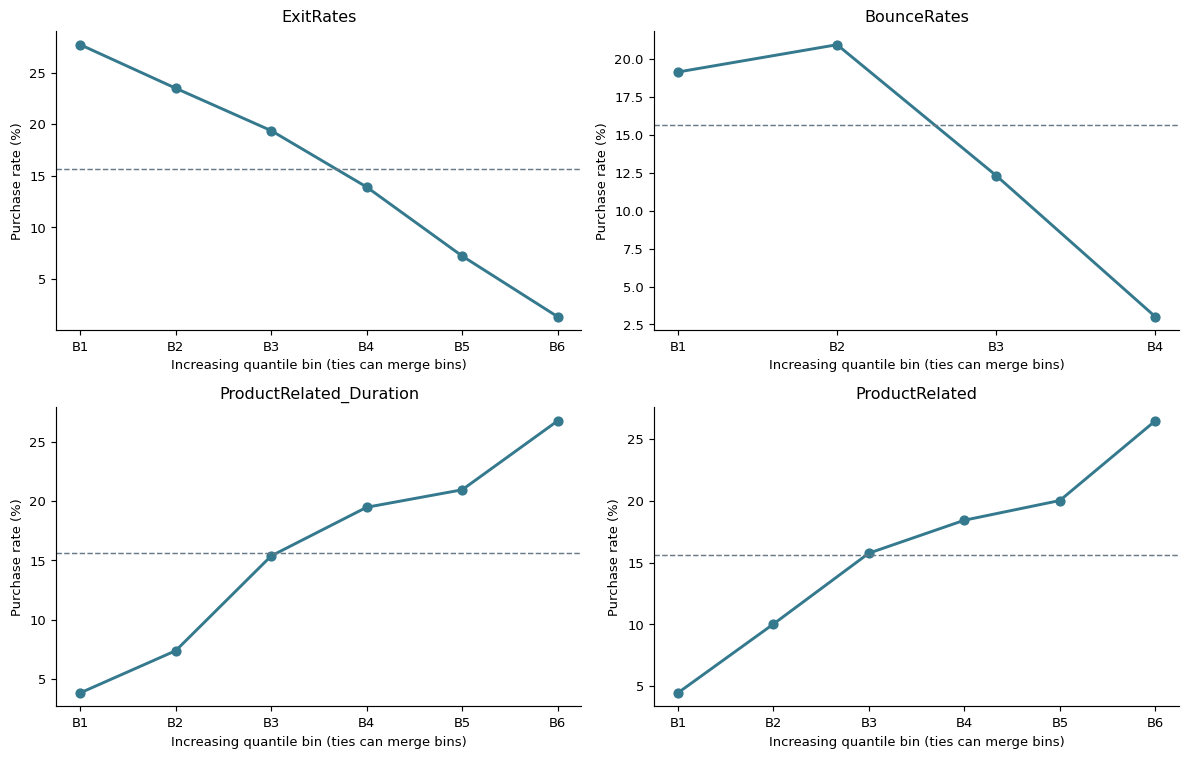

In [ ]:
binned = ["ExitRates","BounceRates","ProductRelated_Duration","ProductRelated"]
fig,axes=plt.subplots(2,2,figsize=(11.4,7.3))
for ax, col in zip(axes.ravel(),binned):
    grp = pd.qcut(df[col],q=6,duplicates="drop")
    agg = df.groupby(grp,observed=True).Revenue.agg(n="size",rate="mean")
    ax.plot(range(len(agg)),100*agg.rate,marker="o",color=BLUE,lw=2)
    ax.axhline(100*df.Revenue.mean(),linestyle="--",color=GRAY,lw=1)
    ax.set_xticks(range(len(agg)),[f"B{i+1}" for i in range(len(agg))])
    ax.set(title=col,xlabel="Increasing quantile bin (ties can merge bins)",ylabel="Purchase rate (%)")
plt.tight_layout();savefig("12_numeric_binned_purchase_rate")

## 15 | Joint engagement profile

The two-feature view is descriptive and does not imply an intervention effect.

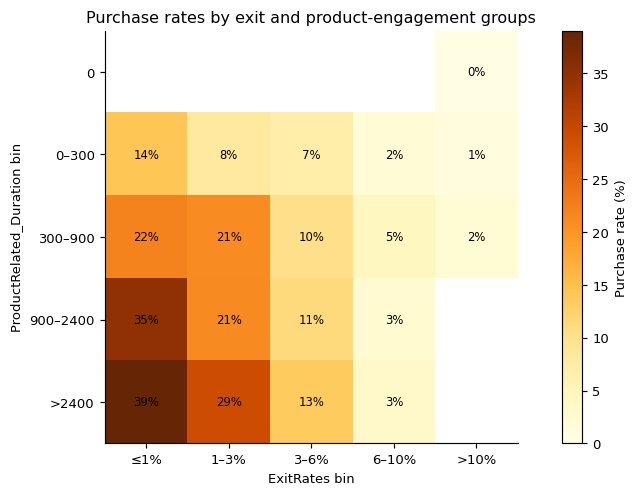

In [ ]:
exit_b = pd.cut(df.ExitRates,bins=[-1e-8, .01, .03, .06, .1, np.inf],
                labels=["≤1%","1–3%","3–6%","6–10%",">10%"])
dur_b = pd.cut(df.ProductRelated_Duration,bins=[-1e-8,0,300,900,2400,np.inf],
               labels=["0","0–300","300–900","900–2400",">2400"])
grp = df.groupby([dur_b,exit_b],observed=False).Revenue.agg(n="size",rate="mean")
mat=grp["rate"].unstack().where(grp["n"].unstack()>=25)*100
fig,ax=plt.subplots(figsize=(8.6,4.8))
im=ax.imshow(mat.to_numpy(),cmap="YlOrBr",vmin=0,vmax=max(25,float(np.nanmax(mat))))
ax.set_xticks(range(len(mat.columns)),mat.columns)
ax.set_yticks(range(len(mat.index)),mat.index)
for i in range(len(mat.index)):
    for j in range(len(mat.columns)):
        v=mat.iloc[i,j]
        if pd.notna(v):ax.text(j,i,f"{v:.0f}%",ha="center",va="center",fontsize=8)
fig.colorbar(im,ax=ax,label="Purchase rate (%)")
ax.set(xlabel="ExitRates bin",ylabel="ProductRelated_Duration bin",title="Purchase rates by exit and product-engagement groups")
plt.tight_layout();savefig("13_exit_duration_heatmap")

## 16 | Page count and duration relationships

Strong associations can produce redundant information for linear baselines.

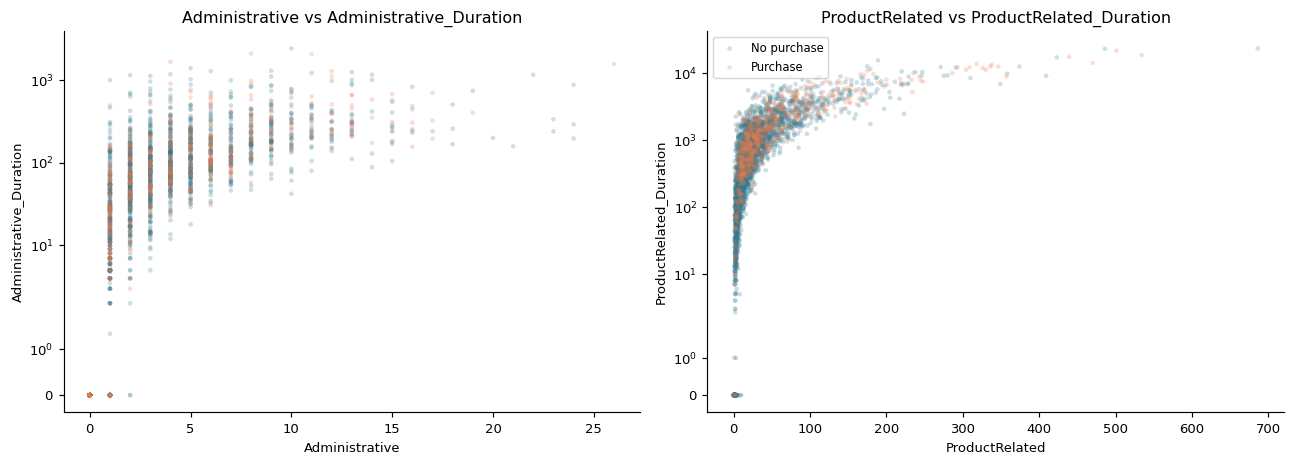

In [ ]:
small=df.sample(n=min(3600,len(df)),random_state=SEED)
fig,axes=plt.subplots(1,2,figsize=(12.4,4.5))
for ax,x,y in zip(axes,["Administrative","ProductRelated"],["Administrative_Duration","ProductRelated_Duration"]):
    for cls,col,label in [(False,BLUE,"No purchase"),(True,ORANGE,"Purchase")]:
        sub=small[small.Revenue==cls]
        ax.scatter(sub[x],sub[y],s=10,alpha=.24,color=col,label=label,edgecolors="none")
    ax.set(xlabel=x,ylabel=y,title=f"{x} vs {y}",yscale="symlog")
axes[1].legend(loc="upper left",fontsize=8)
plt.tight_layout();savefig("14_count_duration_scatter")

## 17 | PageValues sensitivity diagnostics

PageValues may be highly predictive. Its availability before purchase remains unverified.

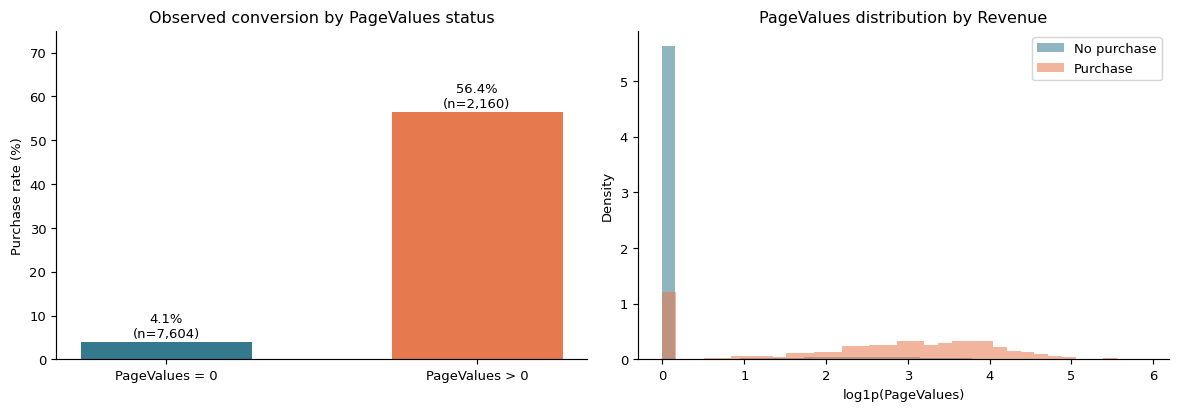

,Sessions,Purchase rate (%)
PageValues,,
False,7604,4.05
True,2160,56.39


In [ ]:
pv_nonzero = df.PageValues.gt(0)
pvagg = df.groupby(pv_nonzero).Revenue.agg(n="size",rate="mean")
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(11.3,4))
labels=["PageValues = 0","PageValues > 0"]
ax1.bar(labels,100*pvagg.rate.values,color=[BLUE,ORANGE],width=.55)
for i,(n,r) in enumerate(zip(pvagg.n,pvagg.rate)):
    ax1.text(i,r*100+1,f"{r:.1%}\n(n={n:,})",ha="center",fontsize=9)
ax1.set(ylabel="Purchase rate (%)",title="Observed conversion by PageValues status",ylim=(0,75))
for outcome,col,label in [(False,BLUE,"No purchase"),(True,ORANGE,"Purchase")]:
    vals=np.log1p(df.loc[df.Revenue==outcome,"PageValues"])
    ax2.hist(vals,bins=35,density=True,alpha=.55,color=col,label=label)
ax2.set(xlabel="log1p(PageValues)",ylabel="Density",title="PageValues distribution by Revenue")
ax2.legend()
plt.tight_layout();savefig("15_pagevalues_zero_positive")
display(pvagg.assign(rate=lambda t:(t.rate*100).round(2)).rename(columns={"n":"Sessions","rate":"Purchase rate (%)"}))

## 18 | Nonzero PageValues groups

A graded association is evidence of predictive signal, not proof of leakage or causality.

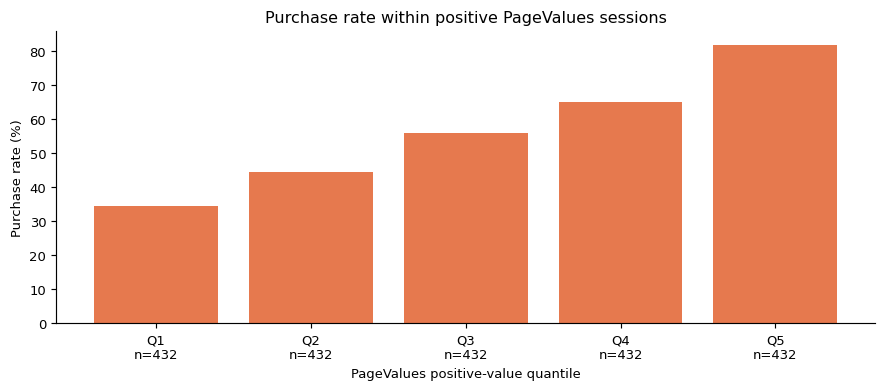

In [ ]:
pvpos=df.loc[df.PageValues.gt(0)].copy()
pvpos["pv_bin"]=pd.qcut(pvpos.PageValues,q=5,duplicates="drop")
a=pvpos.groupby("pv_bin",observed=True).Revenue.agg(n="size",rate="mean")
fig,ax=plt.subplots(figsize=(8.5,3.8))
ax.bar(range(len(a)),a.rate*100,color=ORANGE)
ax.set_xticks(range(len(a)),[f"Q{i+1}\nn={n}" for i,n in enumerate(a.n)])
ax.set(xlabel="PageValues positive-value quantile",ylabel="Purchase rate (%)",title="Purchase rate within positive PageValues sessions")
plt.tight_layout();savefig("16_pagevalues_positive_quintiles")

## 19 | Concise EDA Findings

- **Training Sample:** 9,764 sessions, with a purchase prevalence of 15.63%.
- **Data Quality:** No missing values or exact duplicate rows in the fixed training set.
- **Zero Inflation:** Four numerical features contain over 50% zero values.
- **Feature Correlation:** The strongest non-PageValues Spearman correlation is between `Informational` and `Informational_Duration` (ρ = 0.95).
- **Monthly Patterns:** November has the highest observed purchase rate at 25.8% (n = 2,395).
- **PageValues Sensitivity:** Purchase rates are 4.1% for `PageValues = 0` and 56.4% for `PageValues > 0`. Feature timing and causality remain unverified.
- **Model Integrity:** The original Random Forest and LightGBM training pipelines and the fixed test set remain unchanged.